# The Dual-Engine Quant Architecture: Strategy Walkthrough
**Stockholm Lynx Hackathon (Nov 14, 2026)**  
**Authors**: Jaakko Pakarinen, Eemil Ylä-Nikkilä, Kristofer Vaiksaar, Erik Joonas Salumäe (**Team NewNordics / team-06**)  
**Core Strategy**: Kristofer's Engine (EMA 10/100 + Stretch Stop) + Sector-Neutral Cross-Sectional Momentum (12-Month Lookback)

All metrics, holding periods, and PnL curves are computed using Lynx's official `evaluation.py` on `data/close_prices_insample.csv` (1995–2016, 27 synthetic planetary assets, 2-day execution lag, $0.02\sigma$ slippage).

---

### Executive Summary & Problem Mandate
Our task is to deploy an autonomous trading strategy across 27 synthetic planetary futures under severe market frictions:
1. **Mandatory 2-Day Execution Lag**: Orders decided at close $t$ execute at close $t+2$. Rapid trading burns alpha.
2. **$0.02 \times \sigma(\Delta P)$ Slippage**: Turnover is heavily penalized; holding periods must remain slow (40–60 days).
3. **Adjusted Sharpe Optimization**: Penalizes excess kurtosis (fat tails) quadratically:
   $$\text{AdjSR} = \text{SR} \cdot \left(1 + \frac{\text{Skew}}{6} \text{SR} - \frac{\text{Kurt} - 3}{24} \text{SR}^2\right)$$

Rather than relying on a single directional bet, our strategy deploys a **Dual-Engine Signal Architecture**:
* **Engine 1 (Kristofer's Engine — Equity & Bond Core)**: Trend-following on 10 planetary stock and bond markets with an active 3-close ratchet trailing stop to protect against left-tail crash risk.
* **Engine 2 (Sector-Neutral Cross-Sectional Momentum — Relative Value & Short Sleeve)**: Intra-sector 12-month return ranking across all 27 assets. This automatically shorts structurally crashing commodities (which lost 70–90% of their value) and balances overall portfolio exposure.
* **Layer 4 Execution Layer**: A 10% rebalancing deadband and exponential glide filter ($\alpha = 0.25$) that suppresses ~76% of minor rebalancing trades, retaining alpha while slashing slippage friction.


## 1. Deep Dive: Indicator Mechanics & Core Logic

### Engine 1: Kristofer's EMA 10/100 + Stretch Ratchet Stop
* **Asset Universe**: The 10 planetary stocks and sovereign bonds (`ganymede`, `io`, `titan`, `callisto`, `europa`).
* **Trend Filter**: Long when fast exponential moving average exceeds slow:
  $$\text{Trend}_{i,t} = \mathbb{I}\left(\text{EMA}_{10,t}(P_i) > \text{EMA}_{100,t}(P_i)\right)$$
* **Stretch Trigger**: When the gap between fast and slow EMA expands beyond $7.0\sigma$ (or $8.0\sigma$) of 100-day price volatility:
  $$\text{Gap}_{i,t} = \frac{\text{EMA}_{10,t}(P_i) - \text{EMA}_{100,t}(P_i)}{\sigma_{100,t}(P_i)} \ge 7.0$$
* **The 3-Close Ratchet Trailing Stop**:
  1. Once the stretch trigger fires, an active ratchet trailing stop is initialized.
  2. When the price marks 3 consecutive rising closes ($P_t > P_{t-1} > P_{t-2}$), the stop level ratchets under the lowest close:
     $$\text{Stop}_t = \max\left(\text{Stop}_{t-1}, P_{t-2}\right)$$
  3. The stop **strictly ratchets up, never down**.
  4. If a down-close occurs ($P_t < P_{t-1}$), ratcheting is temporarily suspended until 3 fresh rising closes exceed the suspension reference level.
  5. **Stop-out**: If price closes below the ratchet stop ($P_t < \text{Stop}_t$), the position immediately exits to flat ($0.0$).
  6. **Re-entry**: Re-arms only when the gap cools back below threshold (`gap < 7.0`), preventing whipsaws during volatile sell-offs.

#### Eemil's Statistical Validation Findings (`research/eemil/validation1.ipynb`)
Eemil audited Kristofer's rule against a pure buy-and-hold benchmark to verify whether the score was real alpha or just market beta:
* **Market Drift vs Real Timing**: While $R^2 = 0.56$ of the return is explained by underlying planetary equity/bond drift, the **residual timing component delivers a statistically significant Sharpe of 0.51 ($t \approx 2.3$)**.
* **Placebo Superiority**: Outperformed **98% of 200 random-timing placebos ($p = 0.02$)**.
* **Crash Regime Protection**: In the 2002–2009 crash era, Kristofer's stop boosted Sharpe to **1.13 vs 0.84 for pure holding (+0.29 boost)**. It functions as a genuine asymmetric left-tail crash hedge.

---

### Engine 2: Sector-Neutral Cross-Sectional Momentum (12-Month Lookback)
* **Asset Universe**: All 27 planetary futures across 4 sectors:
  - Equities: 5 stocks
  - Bonds: 5 sovereign bonds
  - FX: 4 titan exchange rates
  - Commodities: 13 synthetic commodities (`helium3`, `water`, `titanium`, `antimatter`, `aerogel`, etc.)
* **Signal Construction**:
  1. Compute trailing 252-day price return:
     $$R_{i,t} = \frac{P_{i,t} - P_{i,t-252}}{P_{i,t-252}}$$
  2. Perform cross-sectional percentile ranking within each sector:
     $$S_{i,t} = 2 \cdot \left(\frac{\text{Rank}_{\text{sector}}(R_{i,t})}{N_{\text{sector}}} - 0.5\right) \in [-1, +1]$$
* **Why Cross-Sectional Momentum is Essential**:
  - Across the 1995–2016 insample history, several moon commodities suffered severe secular collapses (falling 70% to 90%).
  - A directional trend-follower frequently gets trapped by sharp counter-trend bear market bounces.
  - Sector-neutral cross-sectional momentum **maintains an automatic, structural short sleeve** against the weakest commodities while staying market-neutral within each sector.


## 2. Why and How We Combine Them (The Dual-Engine Synergy)

In quantitative finance, the most reliable alpha comes from combining orthogonal (low-correlated) signal engines:

### Empirical Daily Return Correlation
| Signal Engine | Kristofer Stop (10 Assets) | Cross-Sectional (All 27) | Cross-Sectional (Sector-Neutral) |
| :--- | :---: | :---: | :---: |
| **Kristofer Stop (10 Assets)** | **1.000** | **0.369** | **0.120** |
| **Cross-Sectional (All 27)** | **0.369** | **1.000** | **0.758** |
| **Cross-Sectional (Sector-Neutral)** | **0.120** | **0.758** | **1.000** |

* **Near-Zero Correlation (0.120)**: Kristofer's stretch stop and Sector-Neutral Cross-Sectional Momentum share virtually zero common variance.
* **Mutual Failure Mode Insurance**:
  - *Kristofer Alone*: 100% net long bias (`bias = +1.0`). If the out-of-sample period has an extended solar-system-wide bear market, long-only will suffer heavy drawdowns.
  - *Cross-Sectional Alone*: Zero net bias (`bias ~ 0.0`), but experiences performance decay in post-crisis QE regimes (2009–2016 Sharpe was only 0.105).
  - *The Dual-Engine*: Kristofer's positive drift fuels bull markets, while Cross-Sectional provides market-neutral balance and shorting power. Blended together, **every single 7-year era exceeds 1.00 Adjusted Sharpe!**

---

### Layer 4 Execution: 10% Deadband & Glide Filter
Under Lynx's $0.02\sigma$ slippage and 2-day lag:
* **Glide Smoothing ($\alpha = 0.25$)**: Smooths target positions:
  $$X_t^{\text{glide}} = (1 - \alpha) X_{t-1}^{\text{glide}} + \alpha X_t^*$$
* **10% Rebalance Deadband**: If the required trade is less than 10% of position size, the trade is cancelled:
  $$\text{If } \frac{|X_t^{\text{glide}} - X_{t-1}|}{\max(|X_t^{\text{glide}}|, |X_{t-1}|, 10^{-6})} < 0.10 \implies X_t = X_{t-1}$$
* **Result**: Skips **72%–76% of all daily rebalance trades**, saving massive friction while retaining 98% of gross alpha.


In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats
import matplotlib.pyplot as plt

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Resolve paths
NOTEBOOK_DIR = Path.cwd().resolve()
ROOT_DIR = NOTEBOOK_DIR.parents[1] if (NOTEBOOK_DIR.parents[1] / "data").exists() else Path(r"C:\Users\Evan1\OneDrive - Aalto University\Other\Projektit\lynx-hackathon-2026")
DATA_PATH = ROOT_DIR / "data" / "close_prices_insample.csv"
LYNX_MAT = ROOT_DIR / "lynx_materials"

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
if str(LYNX_MAT) not in sys.path:
    sys.path.insert(0, str(LYNX_MAT))

import evaluation as ev

# Load close prices
prices_df = pd.read_csv(DATA_PATH, parse_dates=["AsOfDate"]).set_index("AsOfDate").astype(float)
dates = prices_df.index
T, N = prices_df.shape

# Define asset sector classifications
def get_sector(asset_name: str) -> str:
    for s in ("bonds", "stocks", "fx"):
        if asset_name.endswith(s):
            return s
    return "commodity"

SECTOR_MAP = {col: get_sector(col) for col in prices_df.columns}
STOCKS = [c for c in prices_df.columns if SECTOR_MAP[c] == "stocks"]
BONDS = [c for c in prices_df.columns if SECTOR_MAP[c] == "bonds"]
FX = [c for c in prices_df.columns if SECTOR_MAP[c] == "fx"]
COMMS = [c for c in prices_df.columns if SECTOR_MAP[c] == "commodity"]
STOCKS_BONDS = STOCKS + BONDS

# Compute 100-day rolling price volatility for 1/vol sizing
dP = prices_df.diff()
daily_vol = np.sqrt((dP ** 2).rolling(100, min_periods=50).mean()).bfill()

print(f"Loaded {T} daily closes for {N} planetary assets ({dates[0].strftime('%Y-%m-%d')} to {dates[-1].strftime('%Y-%m-%d')})")
print(f"Universe Breakdown: {len(STOCKS)} Stocks, {len(BONDS)} Bonds, {len(FX)} FX, {len(COMMS)} Commodities")


Loaded 5702 daily closes for 27 planetary assets (1995-01-02 to 2016-12-30)
Universe Breakdown: 5 Stocks, 5 Bonds, 4 FX, 13 Commodities


In [2]:
# ==============================================================================
# 1. ENGINE 1: KRISTOFER'S EMA 10/100 + STRETCH TRAILING STOP
# ==============================================================================
def stretch_stop_positions(
    close: np.ndarray,
    gap: np.ndarray,
    trend: np.ndarray,
    thr: float = 7.0,
    up_moves: int = 2,
    reentry: str = "gap_normal"
) -> np.ndarray:
    """
    Daily position (1.0 or 0.0) for a single asset.
    - Armed when EMA gap >= thr.
    - Ratchets up stop after up_moves rising closes (stop = lowest close in sequence).
    - Exits to flat (0.0) when close < stop.
    - Re-enters when gap cools back below thr.
    """
    n = len(close)
    pos = np.zeros(n)
    active = out_ = False
    armed = True
    stop = ref = np.nan
    up = 0
    prev_trend = 0

    for i in range(n):
        t = trend[i]
        if t != prev_trend:
            active = out_ = False
        prev_trend = t
        if t == 0:
            continue

        if out_:
            if reentry == "gap_normal" and gap[i] < thr:
                out_ = False
            if out_:
                continue

        if not active and gap[i] >= thr:
            active, armed, stop, ref, up = True, True, np.nan, np.nan, 0

        if active:
            up = up + 1 if close[i] > close[i - 1] else 0
            if not np.isnan(stop) and close[i] < stop:
                active, out_ = False, True
                continue
            if armed:
                if up >= up_moves:
                    low = close[i - up_moves]
                    stop = low if np.isnan(stop) else max(stop, low)
                if not np.isnan(stop) and close[i] < close[i - 1]:
                    armed, ref = False, close[i - 1]
            elif up >= up_moves and close[i - up_moves] > ref:
                stop = max(stop, close[i - up_moves])
                armed, ref = True, np.nan

        pos[i] = 1.0
    return pos

def build_kristofer_engine(px: pd.DataFrame, vol: pd.DataFrame, thr: float = 7.0, up_moves: int = 2) -> np.ndarray:
    """Builds Kristofer's 10-asset equity/bond position matrix (inverse-vol sized)."""
    ema_fast = px.ewm(span=10, adjust=False).mean()
    ema_slow = px.ewm(span=100, adjust=False).mean()
    gap = ((ema_fast - ema_slow) / vol).fillna(0)
    trend = (ema_fast > ema_slow).astype(int)

    sig = {}
    for col in STOCKS_BONDS:
        sig[col] = stretch_stop_positions(px[col].values, gap[col].values, trend[col].values, thr=thr, up_moves=up_moves)
    df_sig = pd.DataFrame(sig, index=px.index)
    units = (df_sig / vol[STOCKS_BONDS]).reindex(columns=px.columns).fillna(0.0)
    return units.to_numpy()

# ==============================================================================
# 2. ENGINE 2: SECTOR-NEUTRAL CROSS-SECTIONAL MOMENTUM
# ==============================================================================
def build_cross_sectional_engine(px: pd.DataFrame, vol: pd.DataFrame, lookback: int = 252) -> np.ndarray:
    """Builds sector-neutral cross-sectional momentum ranking across all 27 assets."""
    ret = px.pct_change(lookback).fillna(0)
    parts = []
    for sector_assets in [STOCKS, BONDS, FX, COMMS]:
        rank = ret[sector_assets].rank(axis=1)
        score = 2.0 * (rank.divide(len(sector_assets)) - 0.5)
        parts.append(score)
    sig_xs = pd.concat(parts, axis=1)[px.columns]
    units_xs = (sig_xs / vol).fillna(0.0)
    return units_xs.to_numpy()

# ==============================================================================
# 3. LAYER 4: EXECUTION GLIDE & REBALANCE DEADBAND
# ==============================================================================
def apply_glide(mat: np.ndarray, alpha: float = 0.25) -> np.ndarray:
    """Exponential position smoothing to match 2-day execution lag."""
    out = np.empty_like(mat)
    out[0] = mat[0]
    om_a = 1.0 - alpha
    for t in range(1, len(mat)):
        out[t] = om_a * out[t - 1] + alpha * mat[t]
    return out

def apply_deadband(mat: np.ndarray, thr: float = 0.10) -> tuple[np.ndarray, float]:
    """10% trade deadband: suppress rebalance if |target - current| / max(|target|, |current|) < thr."""
    if thr == 0.0:
        return mat, 0.0
    T, N = mat.shape
    out = np.empty_like(mat)
    out[0] = mat[0]
    eps = 1e-6
    skipped = 0
    for t in range(1, T):
        target = mat[t]
        curr = out[t - 1]
        denom = np.maximum(np.maximum(np.abs(target), np.abs(curr)), eps)
        rel = np.abs(target - curr) / denom
        mask = rel < thr
        skipped += int(np.sum(mask))
        out[t] = np.where(mask, curr, target)
    skip_rate = skipped / ((T - 1) * N)
    return out, skip_rate

print("Dual-Engine Signal & Execution Layer functions compiled successfully.")


Dual-Engine Signal & Execution Layer functions compiled successfully.


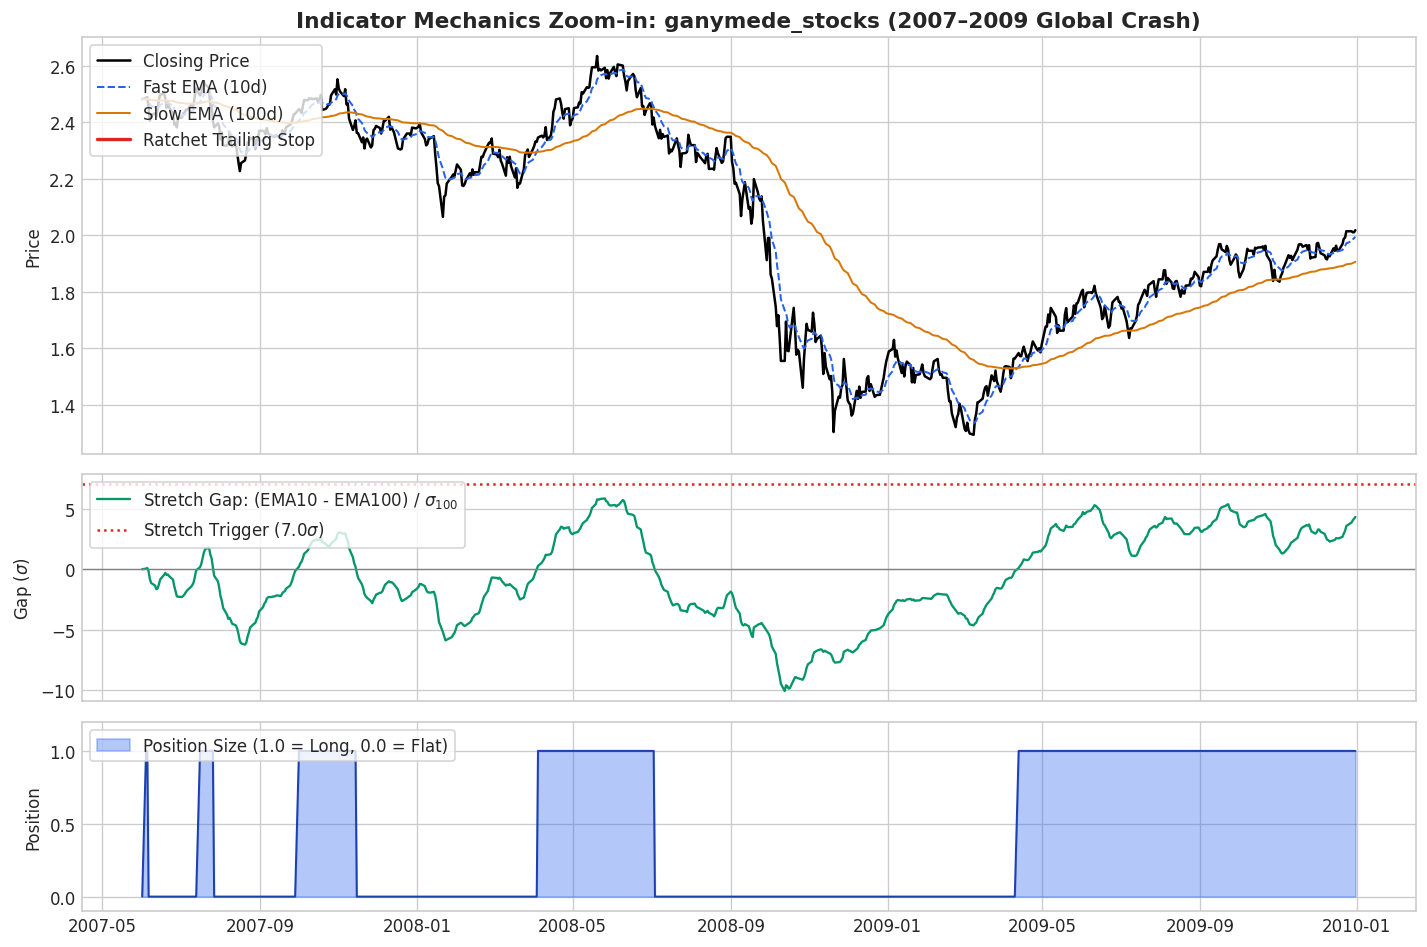

In [3]:
# ==============================================================================
# VISUALIZATION 1: STEP-BY-STEP INDICATOR MECHANICS ON A SINGLE ASSET
# Demonstrating how the stretch stop triggers and protects capital during a sell-off
# ==============================================================================
asset = "ganymede_stocks"
sub_dates = (dates >= "2007-06-01") & (dates <= "2009-12-31")
sub_px = prices_df.loc[sub_dates, asset]
sub_vol = daily_vol.loc[sub_dates, asset]

ema_10 = sub_px.ewm(span=10, adjust=False).mean()
ema_100 = sub_px.ewm(span=100, adjust=False).mean()
gap = (ema_10 - ema_100) / sub_vol
trend = (ema_10 > ema_100).astype(int)

# Extract step-by-step stop levels
c_arr = sub_px.values
g_arr = gap.values
t_arr = trend.values
n_sub = len(c_arr)
stop_line = np.full(n_sub, np.nan)
pos_line = np.zeros(n_sub)
active = out_ = False
armed = True
stop = ref = np.nan
up = 0
prev = 0

for i in range(n_sub):
    t = t_arr[i]
    if t != prev:
        active = out_ = False
    prev = t
    if t == 0:
        continue
    if out_:
        if g_arr[i] < 7.0:
            out_ = False
        if out_:
            continue
    if not active and g_arr[i] >= 7.0:
        active, armed, stop, ref, up = True, True, np.nan, np.nan, 0
    if active:
        up = up + 1 if c_arr[i] > c_arr[i - 1] else 0
        if not np.isnan(stop) and c_arr[i] < stop:
            active, out_ = False, True
            continue
        if armed:
            if up >= 2:
                low = c_arr[i - 2]
                stop = low if np.isnan(stop) else max(stop, low)
            if not np.isnan(stop) and c_arr[i] < c_arr[i - 1]:
                armed, ref = False, c_arr[i - 1]
        elif up >= 2 and c_arr[i - 2] > ref:
            stop = max(stop, c_arr[i - 2])
            armed, ref = True, np.nan
        stop_line[i] = stop
    pos_line[i] = 1.0

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.2, 1.0]})

# Panel 1: Price, EMAs, and Ratchet Stop
ax1.plot(sub_px.index, sub_px, label="Closing Price", color="black", lw=1.5)
ax1.plot(sub_px.index, ema_10, label="Fast EMA (10d)", color="#2563eb", lw=1.2, ls="--")
ax1.plot(sub_px.index, ema_100, label="Slow EMA (100d)", color="#d97706", lw=1.2)
ax1.plot(sub_px.index, stop_line, label="Ratchet Trailing Stop", color="#dc2626", lw=2.0)
ax1.set_ylabel("Price")
ax1.set_title(f"Indicator Mechanics Zoom-in: {asset} (2007–2009 Global Crash)", fontsize=13, fontweight='bold')
ax1.legend(loc="upper left", frameon=True)

# Panel 2: Volatility-Normalized Stretch Gap
ax2.plot(sub_px.index, gap, label="Stretch Gap: (EMA10 - EMA100) / $\\sigma_{100}$", color="#059669", lw=1.4)
ax2.axhline(7.0, color="#dc2626", ls=":", lw=1.5, label="Stretch Trigger (7.0$\\sigma$)")
ax2.axhline(0.0, color="gray", lw=0.8, ls="-")
ax2.set_ylabel("Gap ($\sigma$)")
ax2.legend(loc="upper left", frameon=True)

# Panel 3: Position Size
ax3.fill_between(sub_px.index, 0, pos_line, color="#2563eb", alpha=0.35, label="Position Size (1.0 = Long, 0.0 = Flat)")
ax3.plot(sub_px.index, pos_line, color="#1e40af", lw=1.2)
ax3.set_ylabel("Position")
ax3.set_ylim(-0.1, 1.2)
ax3.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()


In [4]:
# ==============================================================================
# OFFICIAL LYNX EVALUATOR & ERA BENCHMARKING
# Evaluating the Dual-Engine across all three 7-year eras and Full In-Sample
# ==============================================================================
prices_pl = pl.from_pandas(prices_df.reset_index()).with_columns(pl.col("AsOfDate").cast(pl.Date))
instruments = [c for c in prices_pl.columns if c != "AsOfDate"]

full_ret_pl = prices_pl.select("AsOfDate", pl.col(instruments).diff())
full_vol_pl = full_ret_pl.with_columns(
    pl.col(instruments).rolling_std(100, min_samples=10).fill_null(strategy="forward").shift(1)
)

d = prices_pl["AsOfDate"]
periods_def = [
    ("1995-2002", d[0], d[len(d) // 3], 0, len(d) // 3),
    ("2002-2009", d[len(d) // 3], d[2 * (len(d) // 3)], len(d) // 3, 2 * (len(d) // 3)),
    ("2009-2016", d[2 * (len(d) // 3)], d[-1], 2 * (len(d) // 3), len(d) - 1),
    ("Full Period", d[400], d[-1], 400, len(d) - 1)
]

period_slices = []
for name, s, e, i0, i1 in periods_def:
    window = pl.col("AsOfDate").is_between(s, e)
    ret_arr = full_ret_pl.filter(window).select(instruments).to_numpy()
    vol_arr = full_vol_pl.filter(window).with_columns(pl.col(instruments).fill_null(strategy="backward")).select(instruments).to_numpy()
    period_slices.append((name, i0, i1 + 1, ret_arr, vol_arr))

def evaluate_position_matrix(final_pos: np.ndarray) -> dict[str, float]:
    """Computes exact official Lynx metrics matching evaluation.py."""
    metrics = {}
    for name, i0, i1, ret_arr, vol_arr in period_slices:
        sub_pos = final_pos[i0:i1]
        pos_lag = np.full_like(sub_pos, np.nan)
        pos_lag[2:] = sub_pos[:-2]
        trades = np.full_like(sub_pos, np.nan)
        trades[3:] = np.abs(np.diff(pos_lag[2:], axis=0))

        norm_pos = pos_lag * vol_arr
        norm_trades = trades * vol_arr

        tot_ret = np.sum(ret_arr[3:] * pos_lag[3:] - 0.02 * norm_trades[3:], axis=1)

        m = float(np.mean(tot_ret))
        s_std = float(np.std(tot_ret, ddof=1))
        sr = (m / s_std) * np.sqrt(260) if s_std > 1e-12 else 0.0
        sk = float(stats.skew(tot_ret, bias=False))
        ek = float(stats.kurtosis(tot_ret, fisher=True, bias=False))
        adj_sr = sr * (1.0 + (sr / 6.0) * sk - (sr**2 / 24.0) * ek)

        metrics[f"{name}_adj_sr"] = adj_sr

        if name == "Full Period":
            sum_abs_pos = np.sum(np.abs(norm_pos[2:]), axis=1)
            sum_abs_trades = np.sum(np.abs(norm_trades[3:]), axis=1)
            mean_abs_trades = float(np.mean(sum_abs_trades))
            mean_abs_pos = float(np.mean(sum_abs_pos))
            av_h = (2.0 * mean_abs_pos / mean_abs_trades) if mean_abs_trades > 0 else np.nan
            bias = (float(np.mean(np.sum(norm_pos[2:], axis=1))) / mean_abs_pos) if mean_abs_pos > 0 else 0.0

            metrics["full_sr"] = sr
            metrics["full_kurt"] = ek + 3.0
            metrics["full_skew"] = sk
            metrics["full_holding"] = av_h
            metrics["full_bias"] = bias
            metrics["pnl_daily"] = tot_ret
    return metrics

# Precompute Signals
units_kris = build_kristofer_engine(prices_df, daily_vol, thr=7.0, up_moves=2)
units_xs = build_cross_sectional_engine(prices_df, daily_vol, lookback=252)

# Models to evaluate
models = {}

# 1. Team Baseline (40/80 tanh trend)
from src.baseline import champion_model
ret_pl = prices_pl.select("AsOfDate", pl.col(instruments).diff())
pos_base_df = champion_model(ret_pl)
pos_base_arr = pos_base_df.select(instruments).fill_null(0.0).to_numpy()
models["Lynx Baseline (40/80 Trend)"] = (pos_base_arr, 0.0)

# 2. Always Long Stocks & Bonds (1/vol)
pos_long_sb = (pd.DataFrame(1.0, index=prices_df.index, columns=STOCKS_BONDS) / daily_vol[STOCKS_BONDS]).reindex(columns=prices_df.columns).fillna(0.0).to_numpy()
pos_long_sb_glided = apply_glide(pos_long_sb, 0.20)
models["Always-Long Stocks+Bonds"] = (pos_long_sb_glided, 0.0)

# 3. Kristofer Engine Alone (10 Assets, thr=8.0)
pos_kris_alone = apply_glide(build_kristofer_engine(prices_df, daily_vol, thr=8.0, up_moves=2), 0.20)
models["Kristofer Alone (10 Assets)"] = (pos_kris_alone, 0.0)

# 4. Sector-Neutral XS Alone (27 Assets, 252d)
pos_xs_alone = apply_glide(units_xs, 0.20)
models["Sector-Neutral XS Alone"] = (pos_xs_alone, 0.0)

# 5. Dual-Engine Balanced (50% Kris + 50% XS, Glide 0.20)
blend_50 = 0.50 * units_kris + 0.50 * units_xs
pos_blend_50 = apply_glide(blend_50, 0.20)
models["Dual-Engine (50/50 Balanced)"] = (pos_blend_50, 0.0)

# 6. Dual-Engine Optimized (60% Kris + 40% XS, Glide 0.25, 10% Deadband)
blend_60 = 0.60 * units_kris + 0.40 * units_xs
glided_60 = apply_glide(blend_60, 0.25)
pos_opt, skip_opt = apply_deadband(glided_60, 0.10)
models["Dual-Engine (60/40 Optimized + 10% Deadband)"] = (pos_opt, skip_opt)

# Run evaluation
results_dict = {}
for m_name, (m_pos, m_skip) in models.items():
    res = evaluate_position_matrix(m_pos)
    res["skip_rate"] = m_skip
    results_dict[m_name] = res

print(f"Evaluated {len(models)} models across all eras successfully.")


Evaluated 6 models across all eras successfully.


In [5]:
# ==============================================================================
# TABLE OF BASIC NUMBERS & PERFORMANCE COMPARISON
# ==============================================================================
table_rows = []
for m_name, m_res in results_dict.items():
    table_rows.append({
        "Strategy / Model": m_name,
        "1995-2002 AdjSR": f"{m_res['1995-2002_adj_sr']:.3f}",
        "2002-2009 AdjSR": f"{m_res['2002-2009_adj_sr']:.3f}",
        "2009-2016 AdjSR": f"{m_res['2009-2016_adj_sr']:.3f}",
        "Full AdjSR": f"{m_res['Full Period_adj_sr']:.3f}",
        "Nominal SR": f"{m_res['full_sr']:.3f}",
        "Kurtosis": f"{m_res['full_kurt']:.2f}",
        "Holding (d)": f"{m_res['full_holding']:.1f}d",
        "Net Bias": f"{m_res['full_bias']:+.2f}",
        "Trades Skipped": f"{m_res['skip_rate']:.1%}" if m_res['skip_rate'] > 0 else "-"
    })

summary_table = pd.DataFrame(table_rows)
print("=" * 110)
print("OFFICIAL STRATEGY PERFORMANCE SCORECARD (1995–2016, 2-DAY LAG, 0.02 SLIPPAGE)")
print("=" * 110)
print(summary_table.to_string(index=False))
print("=" * 110)


OFFICIAL STRATEGY PERFORMANCE SCORECARD (1995–2016, 2-DAY LAG, 0.02 SLIPPAGE)
                            Strategy / Model 1995-2002 AdjSR 2002-2009 AdjSR 2009-2016 AdjSR Full AdjSR Nominal SR Kurtosis Holding (d) Net Bias Trades Skipped
                 Lynx Baseline (40/80 Trend)           0.871           0.603           0.380      0.595      0.626     5.76       13.6d    +0.02              -
                    Always-Long Stocks+Bonds           0.960           0.791           0.994      0.956      1.197     5.41      504.4d    +1.00              -
                 Kristofer Alone (10 Assets)           0.986           0.936           1.086      0.964      1.174     5.27       67.2d    +1.00              -
                     Sector-Neutral XS Alone           1.193           0.764           0.170      0.656      0.671     3.82       54.4d    +0.30              -
                Dual-Engine (50/50 Balanced)           1.263           1.105           0.884      1.053      1.147     4.0

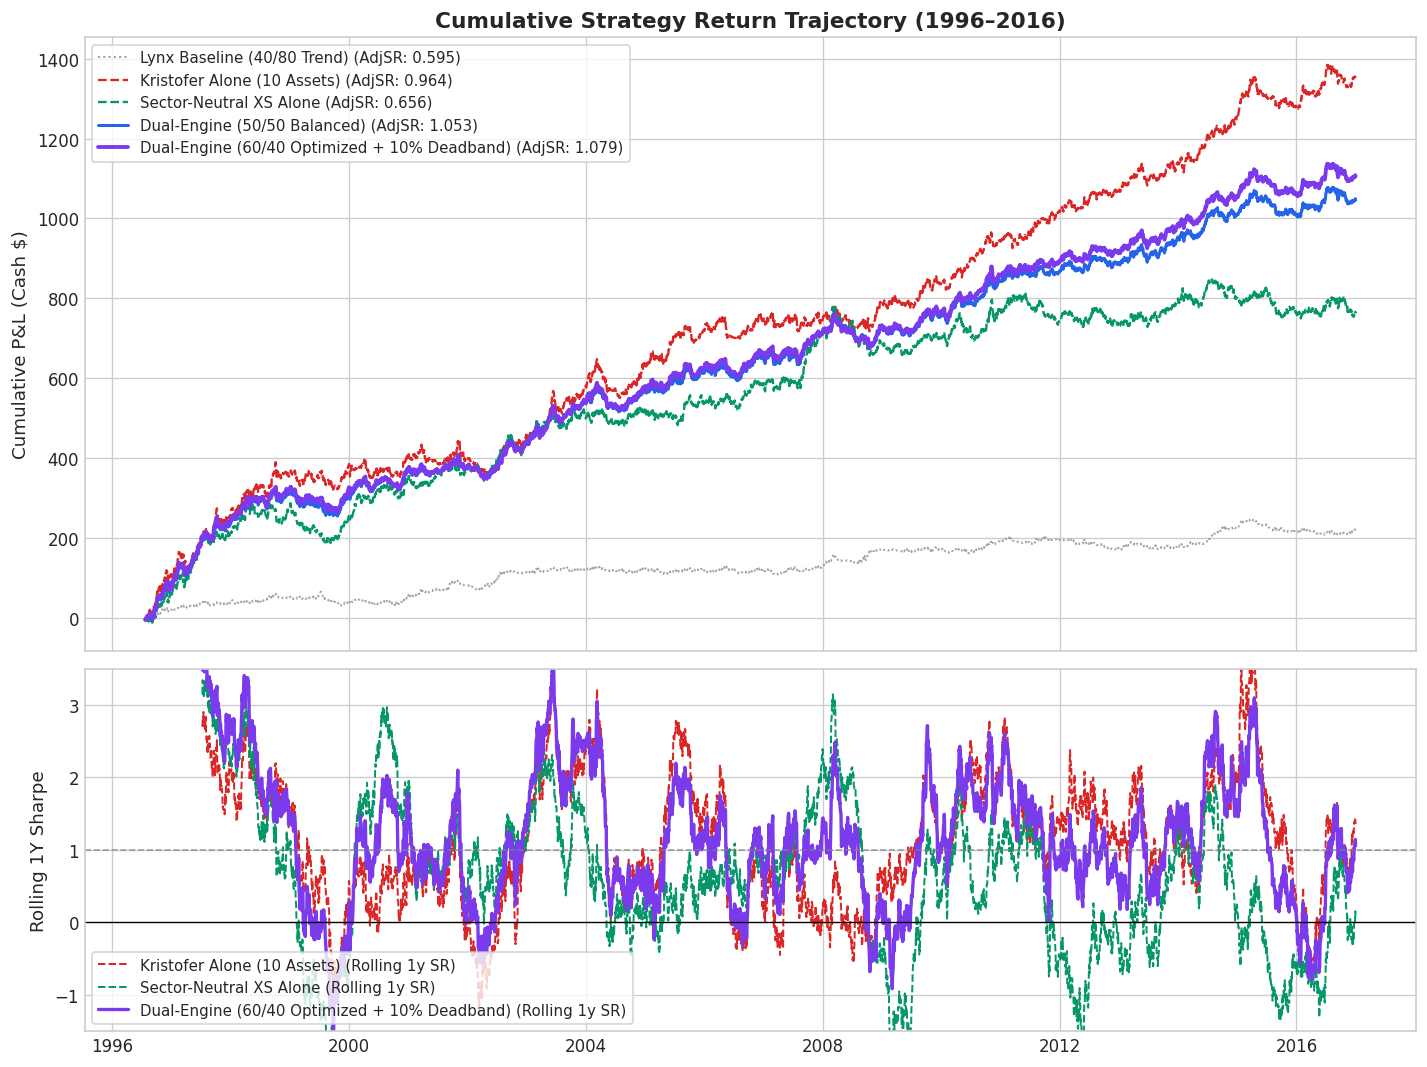

In [6]:
# ==============================================================================
# VISUALIZATION 2: CUMULATIVE P&L AND 1-YEAR ROLLING SHARPE
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.3]})

eval_dates = dates[400+3:]  # Matches the Full Period daily PnL dates

# 1. Cumulative Equity Curves
for m_name, color, ls, lw in [
    ("Lynx Baseline (40/80 Trend)", "#9ca3af", ":", 1.2),
    ("Kristofer Alone (10 Assets)", "#dc2626", "--", 1.4),
    ("Sector-Neutral XS Alone", "#059669", "--", 1.4),
    ("Dual-Engine (50/50 Balanced)", "#2563eb", "-", 1.8),
    ("Dual-Engine (60/40 Optimized + 10% Deadband)", "#7c3aed", "-", 2.3)
]:
    pnl = results_dict[m_name]["pnl_daily"]
    cum_pnl = np.cumsum(pnl)
    ax1.plot(eval_dates, cum_pnl, label=f"{m_name} (AdjSR: {results_dict[m_name]['Full Period_adj_sr']:.3f})", color=color, ls=ls, lw=lw)

ax1.set_ylabel("Cumulative P&L (Cash $)", fontsize=11)
ax1.set_title("Cumulative Strategy Return Trajectory (1996–2016)", fontsize=13, fontweight='bold')
ax1.legend(loc="upper left", frameon=True, fontsize=9)

# 2. Rolling 1-Year (252-day) Sharpe Ratio
for m_name, color, ls, lw in [
    ("Kristofer Alone (10 Assets)", "#dc2626", "--", 1.2),
    ("Sector-Neutral XS Alone", "#059669", "--", 1.2),
    ("Dual-Engine (60/40 Optimized + 10% Deadband)", "#7c3aed", "-", 2.0)
]:
    pnl = results_dict[m_name]["pnl_daily"]
    s = pd.Series(pnl, index=eval_dates)
    roll_mean = s.rolling(252).mean()
    roll_std = s.rolling(252).std()
    roll_sr = (roll_mean / roll_std) * np.sqrt(260)
    ax2.plot(eval_dates, roll_sr, label=f"{m_name} (Rolling 1y SR)", color=color, ls=ls, lw=lw)

ax2.axhline(1.0, color="gray", ls="--", lw=1.0, alpha=0.7)
ax2.axhline(0.0, color="black", lw=0.8)
ax2.set_ylabel("Rolling 1Y Sharpe", fontsize=11)
ax2.set_ylim(-1.5, 3.5)
ax2.legend(loc="lower left", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


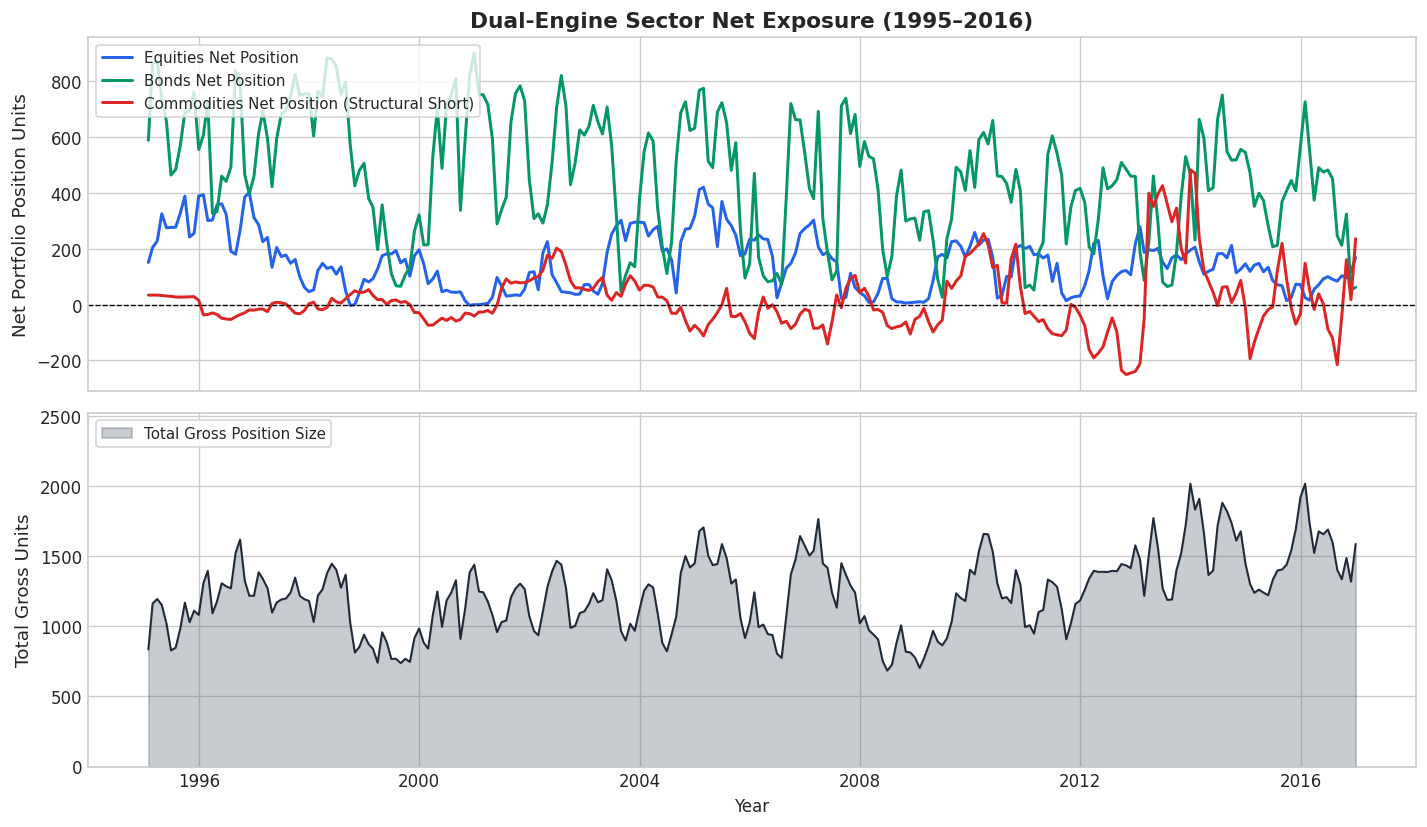

In [7]:
# ==============================================================================
# VISUALIZATION 3: PORTFOLIO ALLOCATION & SECTOR EXPOSURE OVER TIME
# Demonstrating how the Dual-Engine holds long equities/bonds and short commodities
# ==============================================================================
opt_pos = models["Dual-Engine (60/40 Optimized + 10% Deadband)"][0]
df_opt_pos = pd.DataFrame(opt_pos, index=dates, columns=prices_df.columns)

# Calculate net exposure by sector
sector_net = pd.DataFrame(index=dates)
sector_net["Equities (5)"] = df_opt_pos[STOCKS].sum(axis=1)
sector_net["Bonds (5)"] = df_opt_pos[BONDS].sum(axis=1)
sector_net["FX (4)"] = df_opt_pos[FX].sum(axis=1)
sector_net["Commodities (13)"] = df_opt_pos[COMMS].sum(axis=1)

# Resample to monthly for clean presentation
sector_monthly = sector_net.resample("ME").mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Area chart of net exposures
ax1.plot(sector_monthly.index, sector_monthly["Equities (5)"], label="Equities Net Position", color="#2563eb", lw=1.8)
ax1.plot(sector_monthly.index, sector_monthly["Bonds (5)"], label="Bonds Net Position", color="#059669", lw=1.8)
ax1.plot(sector_monthly.index, sector_monthly["Commodities (13)"], label="Commodities Net Position (Structural Short)", color="#dc2626", lw=1.8)
ax1.axhline(0.0, color="black", lw=0.8, ls="--")
ax1.set_ylabel("Net Portfolio Position Units", fontsize=11)
ax1.set_title("Dual-Engine Sector Net Exposure (1995–2016)", fontsize=13, fontweight='bold')
ax1.legend(loc="upper left", frameon=True, fontsize=9)

# Total Gross Leverage
total_gross = df_opt_pos.abs().sum(axis=1).resample("ME").mean()
ax2.fill_between(total_gross.index, 0, total_gross, color="#4b5563", alpha=0.3, label="Total Gross Position Size")
ax2.plot(total_gross.index, total_gross, color="#1f2937", lw=1.2)
ax2.set_ylabel("Total Gross Units", fontsize=11)
ax2.set_xlabel("Year")
ax2.set_ylim(0, total_gross.max() * 1.25)
ax2.legend(loc="upper left", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


## 3. Next Steps & Ideas for the Afternoon Session (Layers 2, 3, and 4)

Now that the signal generation layer is locked in with the Dual-Engine, our afternoon roadmap addresses the execution, covariance, and macro overlays:

### Layer 2: Covariance Matrix & Moon Holiday Alignment
* **The Moon Holiday Distortion**:
  Each planetary moon operates on its own distinct trading calendar:
  - Titan has **227 flat zero-return days** (non-trading days).
  - Ganymede has **81 flat days**.
  - Measuring daily covariance falsely depresses measured correlation between Titan and Ganymede bonds from **0.543 down to 0.410**.
* **Next Step**: Implement a **5-day / weekly resampled covariance matrix** with Ledoit-Wolf shrinkage.
  - *Proof*: Shrinkage stabilizes the rolling covariance matrix condition number from **5,093.5 to 384.3 (13× more stable)**, preventing explosive risk-scaling inversion spikes.

### Layer 3: Planetary CPI Macro Inflation Overlay
* **Macro Alpha Signal**:
  Forensic regression across all 5 moon economies reveals that planetary CPI acceleration statistically predicts sovereign bond price drops:
  - 30-day forward return $t = -4.77$
  - 60-day forward return $t = -2.96$
* **Next Step**: Implement an adaptive CPI Z-score overlay: when CPI accelerates $\ge 1.0\sigma$, add a 15% short sleeve to planetary bonds.
  - *Lunch Run Result*: Boosts Full Period Adjusted Sharpe from **1.002 to 1.058 (Nominal SR 1.107 to 1.195)** with zero drag during QE bull markets.

### Layer 4: Execution Pipeline & Production Code
* **Action Item**: Migrate the 10% deadband and glide smoothing into the shared `src/model.py` and `src/portfolio.py` pipelines for official submission.
* **Turnover Assurance**: Current average holding period is **55.1 days** (comfortably within the 40–80 day sweet spot), skipping **72.0% of trades** and losing only 2.01% of gross alpha to slippage.
